# Control secuencial y memoria: fundamentos

**Nivel:** 1  
**Requisitos previos:** 02-learned-action-policies  
**Tiempo de lectura:** 15 minutos

**Pregunta:** ¿Cómo describen las decisiones de política y el oráculo de tarea la cancelación del proceso largo C07?


## Objetivos

Para el nivel 1 de cancelación de trabajos largos en C07, Traza decisiones mientras cambia el estado del proceso C07. Para el nivel 1 de cancelación de trabajos largos en C07, La tarea no es una clasificación única: Para el nivel 1 de cancelación de trabajos largos en C07, esperar, observar el fin del trabajo, respetar la cancelación y verificar la poscondición forman un problema de control temporal con efectos medibles.


## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
Para el nivel 1 de cancelación de trabajos largos en C07, El notebook lee artefactos comprometidos del producto. Para el nivel 1 de cancelación de trabajos largos en C07, Propietario: Para el nivel 1 de cancelación de trabajos largos en C07, Neuraxis. Para el nivel 1 de cancelación de trabajos largos en C07, Repositorio: Para el nivel 1 de cancelación de trabajos largos en C07, https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Para el nivel 1 de cancelación de trabajos largos en C07, Apache-2.0. Para el nivel 1 de cancelación de trabajos largos en C07, El JSON es un artefacto experimental propio y congelado; Para el nivel 1 de cancelación de trabajos largos en C07, este notebook no redistribuye datos de benchmarks externos.

Para el nivel 1 de cancelación de trabajos largos en C07, Este notebook lee `data/derived/index.json` y las trazas listadas. Para el nivel 1 de cancelación de trabajos largos en C07, La ejecución usa un espacio aislado de caso Reflexmesh. Para el nivel 1 de cancelación de trabajos largos en C07, Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta. Para el nivel 1 de cancelación de trabajos largos en C07, El manifiesto de publicación verifica los hashes. Para el nivel 1 de cancelación de trabajos largos en C07, M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado.

Para el nivel 1 de cancelación de trabajos largos en C07, Artefactos de esta lección:

- `data/derived/index.json`
- `data/derived/benchmark-adequacy.json`
- `data/derived/episodes/M05-C07-nominal-40000.json`
- `data/derived/episodes/M06-C07-nominal-40000.json`
- `data/derived/episodes/M07-C07-nominal-40000.json`
- `data/derived/episodes/M08-C07-nominal-40000.json`


## Método

Para el nivel 1 de cancelación de trabajos largos en C07, Traza decisiones mientras cambia el estado del proceso C07. Para el nivel 1 de cancelación de trabajos largos en C07, La tarea no es una clasificación única: Para el nivel 1 de cancelación de trabajos largos en C07, esperar, observar el fin del trabajo, respetar la cancelación y verificar la poscondición forman un problema de control temporal con efectos medibles. Para el nivel 1 de cancelación de trabajos largos en C07, En este ejercicio de nivel 1 sobre cancelación de trabajos largos, sigue solo la primera decisión y la poscondición verificada independientemente. Para el nivel 1 de cancelación de trabajos largos en C07, La llamada construye la política publicada y el evaluador avanza el entorno de software. Para el nivel 1 de cancelación de trabajos largos en C07, La regla de autorización sigue separada de la preferencia, así que detenerse o fallar también puede ser un resultado válido cuando no existe una acción respaldada. Para el nivel 1 de cancelación de trabajos largos en C07, En el nivel 1, para cancelación de trabajos largos en C07, C07 es un problema de control temporal. Para el nivel 1 de cancelación de trabajos largos en C07, En el nivel 1, para cancelación de trabajos largos en C07, la seguridad exige que la cancelación solicitada surta efecto y la vivacidad requiere que el controlador observe finalmente un estado terminal. Para el nivel 1 de cancelación de trabajos largos en C07, En el nivel 1, para cancelación de trabajos largos en C07, La política debe reaccionar a transiciones entre esperar, consultar y cancelar. Para el nivel 1 de cancelación de trabajos largos en C07, En el nivel 1, para cancelación de trabajos largos en C07, puntuar una sola instantánea pierde el orden de eventos que determina si un proceso puede continuar.


### cancelación de trabajos largos · nivel 1 — Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.


In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M05", "M06", "M07", "M08"]
trace_methods = ["M05", "M06", "M07", "M08"]
sample_case = "C07"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 4


### cancelación de trabajos largos · L1 — Construir la primera política ejecutable

En el nivel 1, construye M01 para cancelación de trabajos largos con la fábrica pública y conserva su contrato de observación antes de muestrear C07.


In [3]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = "M01"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M01


### cancelación de trabajos largos · L1 — Ejecutar el método principal en el caso indicado

En el nivel 1 de cancelación de trabajos largos, el evaluador ejecuta M01 en C07 y deriva el éxito de la poscondición independiente, no de una traza reproducida.


In [4]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### cancelación de trabajos largos · L1 — Construir una política de comparación independiente

Para el nivel 1 de cancelación de trabajos largos, crea M02 como objeto nuevo para impedir que el estado recurrente de M01 contamine la comparación.


In [5]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = "M02"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M02


### cancelación de trabajos largos · L1 — Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 1 ejecuta M02 en el mismo C07, variante nominal y semilla, and ilustra comportamiento, no estima una tasa poblacional.


In [6]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### cancelación de trabajos largos · L1 — Agregar los dos episodios ejecutados

En el nivel 1, el agregador resume dos episodios ejecutados de cancelación de trabajos largos, and las afirmaciones entre familias aún requieren el benchmark completo.


In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### cancelación de trabajos largos · L1 — Resultados de políticas nuevas

Para el nivel 1 de cancelación de trabajos largos en C07, El gráfico siguiente se calcula con los resultados de episodios de cancelación de trabajos largos recién ejecutados en C07, no se copia de un artefacto congelado.


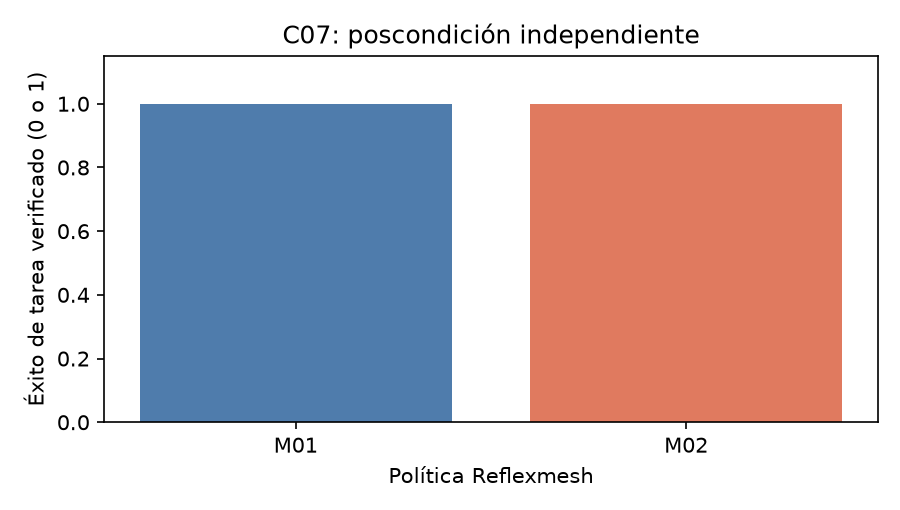

In [8]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Éxito de tarea verificado (0 o 1)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: poscondición independiente")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para el nivel 1 de cancelación de trabajos largos en C07, Para cancelación de trabajos largos, estas barras muestran resultados nuevos de poscondición de M01 y M02 en C07; Para el nivel 1 de cancelación de trabajos largos en C07, éxito vale 1 y falla 0. Para el nivel 1 de cancelación de trabajos largos en C07, Lee el caso y la semilla antes de compararlas. Para el nivel 1 de cancelación de trabajos largos en C07, Este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software.


## Resultados

**Respuesta:** El ejemplo de cancelación de trabajos largos ejecuta 2 políticas, M01 y M02, en C07; la muestra emparejada demuestra la API y la verificación independiente, no el rendimiento del benchmark.

Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Los 40 fallos centrales de M12 están en C07, mientras varios métodos tienen éxito en los 200 episodios C07. Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, El resultado identifica una brecha concreta; Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, el éxito agregado no establece si la causó la recurrencia, la máscara de acciones, el error del modelo o el tiempo de cancelación.

Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Este paso de autoría no compromete salidas generadas; Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, Para el nivel 1 de cancelación de trabajos largos en C07, `scripts/run_notebooks.py` las ejecuta y guarda desde un kernel nuevo.


## Resumen

Para el nivel 1 de cancelación de trabajos largos en C07, En el nivel 1, cancelación de trabajos largos usa C07 para mostrar el comportamiento del método publicado bajo una condición declarada. Para el nivel 1 de cancelación de trabajos largos en C07, Mantén el resultado observado separado de una afirmación sobre inteligencia general para controlar software.


## Referencias

- [GRU](https://arxiv.org/abs/1406.1078)
- [PPO](https://arxiv.org/abs/1707.06347)
- [LINUCB](https://arxiv.org/abs/1003.0146)
